In [4]:
# Setup: mount Drive, paths, helper functions  (about 30 s)
from google.colab import drive
drive.mount('/content/drive')

import os, gc, time, pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import genpareto

DATA = '/content/drive/MyDrive/mlkem_dataset'
BASE = f'{DATA}/extracted/d0nj0n_mlkem_dataset'
PQM4 = f'{BASE}/pqm4-ref/pqm4'
REF = f'{BASE}/pqm4-ref/ref'
MASK_FIXED = f'{BASE}/masked/100k_capture_fixedkey_all'
MASK_VAR = f'{BASE}/masked/100k_capture_all_2'
Q = 3329
plt.rcParams['figure.dpi'] = 110

def hw(values):
    """Hamming weight (number of 1-bits) of each value."""
    v = np.ascontiguousarray(np.asarray(values).ravel().astype(np.uint16))
    return np.unpackbits(v.view(np.uint8).reshape(-1, 2), axis=1).sum(axis=1).astype(np.int64)

def load_secret_col0(impl, key_type, chunk):
    """Coefficient 0 of the secret operand a (pqm4 / ref)."""
    root = PQM4 if impl == 'pqm4' else REF
    a = np.load(f'{root}/{key_type}/metadata/mult_a_{chunk}.npy')
    if a.dtype == np.uint8:              # ref stores int16 values as raw little-endian bytes
        a = a.view('<i2')
    return a[:, 0].astype(np.int64)

def welch_t(traces, labels):
    """TVLA-style Welch t-test per sample: HW <= median vs HW > median."""
    low = labels <= np.median(labels)
    a, b = traces[low].astype(np.float32), traces[~low].astype(np.float32)
    va, vb = a.var(0, ddof=1), b.var(0, ddof=1)
    return (b.mean(0) - a.mean(0)) / np.sqrt(va / len(a) + vb / len(b))

def select_poi(score, k=50, min_distance=20, stop_at_zero=False):
    """Greedy top-k peaks at least min_distance samples apart (the Stage 4 / Stage 6 rule)."""
    s = np.abs(np.asarray(score, dtype=np.float64)).copy()
    chosen = []
    for _ in range(k):
        i = int(np.argmax(s))
        if not np.isfinite(s[i]) or (stop_at_zero and s[i] <= 0):
            break
        chosen.append(i)
        s[max(0, i - min_distance): i + min_distance + 1] = -np.inf
    return np.array(chosen, dtype=np.int64)

print('Setup done. Dataset folder found:', os.path.isdir(BASE))

Mounted at /content/drive
Setup done. Dataset folder found: True


In [5]:
# Stages 1-2: dataset shape and ground-truth checks  (about 20 s)
for name, path in [('pqm4 profiling', f'{PQM4}/variable_key/leakages/traces_0.npy'),
                   ('ref profiling', f'{REF}/variable_key/leakages/traces_0.npy'),
                   ('mkm4 share 0', f'{MASK_VAR}/traces/traces_s0_0.npy')]:
    arr = np.load(path, mmap_mode='r')
    print(f'{name:15s} one file = {arr.shape[0]:,} traces x {arr.shape[1]:,} samples ({arr.dtype})')

# ref metadata is raw bytes: which byte order gives valid coefficients 0..3328?
raw = np.load(f'{REF}/variable_key/metadata/mult_a_0.npy')
for order, label in [('<i2', 'little-endian'), ('>i2', 'big-endian')]:
    v = raw.view(order)
    print(f'ref read as {label:13s}: {np.mean((v >= 0) & (v < Q)):7.2%} of values are valid coefficients')

print()
for impl in ['pqm4', 'ref']:
    s = np.unique(load_secret_col0(impl, 'fixed_key', 0))
    print(f'{impl:5s} attack set: secret coefficient 0 = {s}, HW = {hw(s)}')
b0 = np.load(f'{MASK_FIXED}/metadata/bp_s0_0.npy')[:, 0].astype(np.int64)
b1 = np.load(f'{MASK_FIXED}/metadata/bp_s1_0.npy')[:, 0].astype(np.int64)
secret_mk = np.unique((b0 + b1) % Q)
print(f'mkm4  attack set: share b0 takes {len(np.unique(b0)):,} different values, '
      f'but (b0 + b1) mod q = {secret_mk}, HW = {hw(secret_mk)}')

pqm4 profiling  one file = 10,000 traces x 20,000 samples (int16)
ref profiling   one file = 10,000 traces x 13,000 samples (int16)
mkm4 share 0    one file = 10,000 traces x 10,000 samples (int16)
ref read as little-endian: 100.00% of values are valid coefficients
ref read as big-endian   :   5.15% of values are valid coefficients

pqm4  attack set: secret coefficient 0 = [679], HW = [6]
ref   attack set: secret coefficient 0 = [1026], HW = [2]
mkm4  attack set: share b0 takes 3,149 different values, but (b0 + b1) mod q = [1681], HW = [5]


ref profiling traces: 100,000
class counts HW0..HW11: [   24   358  2001  6466 14454 22053 23371 17937  9359  3294   618    65]
most common class: HW6 (prior 0.2337) -> majority baseline 23.4%


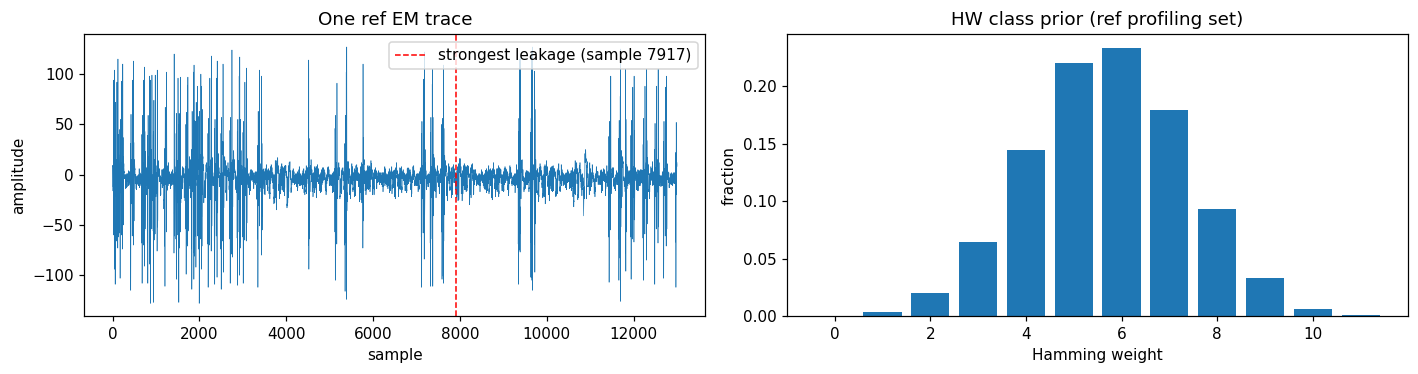

In [6]:
# Hamming-weight labels and class prior for the ref profiling set  (about 20 s)
ref_labels = np.concatenate([hw(load_secret_col0('ref', 'variable_key', i)) for i in range(10)])
counts = np.bincount(ref_labels, minlength=12)
prior = counts / counts.sum()
print(f'ref profiling traces: {len(ref_labels):,}')
print('class counts HW0..HW11:', counts)
print(f'most common class: HW{prior.argmax()} (prior {prior.max():.4f}) -> majority baseline {prior.max():.1%}')

trace = np.load(f'{REF}/variable_key/leakages/traces_0.npy', mmap_mode='r')[0]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(trace, lw=0.4)
ax[0].axvline(7917, color='r', ls='--', lw=1, label='strongest leakage (sample 7917)')
ax[0].set(title='One ref EM trace', xlabel='sample', ylabel='amplitude'); ax[0].legend()
ax[1].bar(range(12), prior)
ax[1].set(title='HW class prior (ref profiling set)', xlabel='Hamming weight', ylabel='fraction')
plt.tight_layout(); plt.show()

pqm4           max |t| =  168.39 at sample   183 | max SNR = 1.1352
ref            max |t| =   55.19 at sample  7917 | max SNR = 0.2739
mkm4 (secret)  max |t| =    3.20 at sample  1647 | max SNR = 0.0428


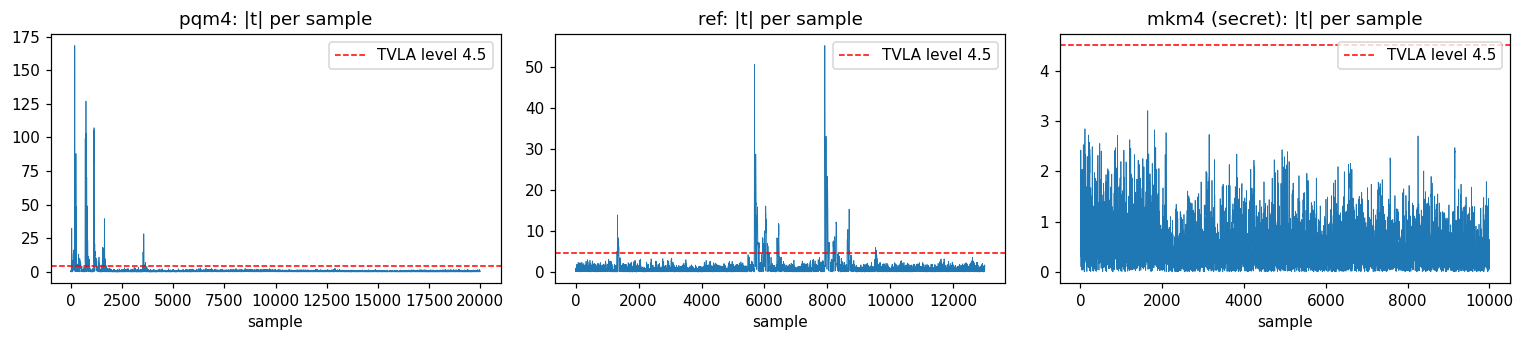

In [7]:
# Stage 3 results on the complete profiling sets (saved arrays, instant)
full = np.load(f'{DATA}/baseline_full_pqm4_ref.npz')
mk = np.load(f'{DATA}/masked_baseline_v2.npz')
T = {'pqm4': full['pqm4_tvla'], 'ref': full['ref_tvla'], 'mkm4 (secret)': mk['tvla']}
S = {'pqm4': full['pqm4_snr'], 'ref': full['ref_snr'], 'mkm4 (secret)': mk['snr']}
for k in T:
    t = np.abs(T[k])
    print(f'{k:14s} max |t| = {t.max():7.2f} at sample {t.argmax():5d} | max SNR = {S[k].max():.4f}')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, k in zip(axes, T):
    ax.plot(np.abs(T[k]), lw=0.5)
    ax.axhline(4.5, color='r', ls='--', lw=1, label='TVLA level 4.5')
    ax.set(title=f'{k}: |t| per sample', xlabel='sample'); ax.legend()
plt.tight_layout(); plt.show()

In [8]:
# Stage 3 live: ref on one file, and the masked positive control  (about 1-2 min)
ref_chunk = np.load(f'{REF}/variable_key/leakages/traces_0.npy')
t_live = np.abs(welch_t(ref_chunk, hw(load_secret_col0('ref', 'variable_key', 0))))
print(f'ref, 10,000 traces (live): max |t| = {t_live.max():.2f} at sample {t_live.argmax()}   '
      f'[full 100,000 traces: 55.19 at 7917]')
del ref_chunk; gc.collect()

mk_chunk = np.load(f'{MASK_VAR}/traces/traces_s0_0.npy')
mb0 = np.load(f'{MASK_VAR}/metadata/bp_s0_0.npy')[:, 0].astype(np.int64)
mb1 = np.load(f'{MASK_VAR}/metadata/bp_s1_0.npy')[:, 0].astype(np.int64)
t_secret = np.abs(welch_t(mk_chunk, hw((mb0 + mb1) % Q)))
t_share = np.abs(welch_t(mk_chunk, hw(mb0)))
print(f'mkm4, 10,000 traces, labelled by the SECRET: max |t| = {t_secret.max():6.2f}   [full 100,000 traces: 3.20]')
print(f'mkm4, 10,000 traces, labelled by SHARE b0  : max |t| = {t_share.max():6.2f} at sample {t_share.argmax()}   '
      f'[full 100,000 traces: 262.83 at 516]')
del mk_chunk; gc.collect()

ref, 10,000 traces (live): max |t| = 18.69 at sample 7918   [full 100,000 traces: 55.19 at 7917]
mkm4, 10,000 traces, labelled by the SECRET: max |t| =   4.08   [full 100,000 traces: 3.20]
mkm4, 10,000 traces, labelled by SHARE b0  : max |t| =  85.11 at sample 516   [full 100,000 traces: 262.83 at 516]


33

pqm4           u =  9.676  xi = +0.5639  sigma =  13.051  excesses =  400  max score = 1.588  points: top-50 -> EVT 27
ref            u =  9.964  xi = +0.0810  sigma =   8.764  excesses =  260  max score = 1.873  points: top-50 -> EVT 15
mkm4 (secret)  u =  1.898  xi = -0.1769  sigma =   0.346  excesses =  200  max score = 2.705  points: top-50 -> EVT 50

Worked example (pqm4): y = 158.71, 1 + xi*y/sigma = 7.857, survival = 0.0258, score = 1.588


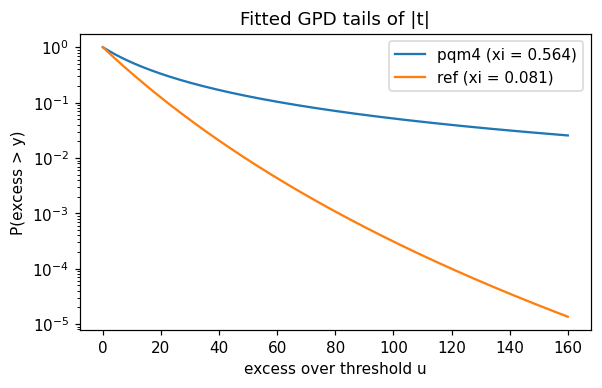

In [9]:
# Stages 4-6: GPD fit and EVT cut-off, live on the saved full |t| arrays  (about 5 s)
def evt_cutoff(t, tail_fraction=0.02, k=50, min_distance=20):
    a = np.abs(t)
    u = np.quantile(a, 1 - tail_fraction)
    exc = a[a > u] - u
    xi, _, sigma = genpareto.fit(exc, floc=0)
    score = np.zeros_like(a, dtype=np.float64)
    m = a > u
    score[m] = -np.log10(np.clip(genpareto.sf(a[m] - u, xi, loc=0, scale=sigma), 1e-300, 1))
    return u, xi, sigma, len(exc), score, select_poi(a, k, min_distance), select_poi(score, k, min_distance, stop_at_zero=True)

evt_res = {}
for k in T:
    u, xi, sigma, n_exc, score, top50, evt = evt_cutoff(T[k])
    evt_res[k] = (u, xi, sigma)
    print(f'{k:14s} u = {u:6.3f}  xi = {xi:+.4f}  sigma = {sigma:7.3f}  excesses = {n_exc:4d}  '
          f'max score = {score.max():.3f}  points: top-50 -> EVT {len(evt)}')

u, xi, sigma = evt_res['pqm4']
y = np.abs(T['pqm4']).max() - u
z = 1 + xi * y / sigma
print(f'\nWorked example (pqm4): y = {y:.2f}, 1 + xi*y/sigma = {z:.3f}, '
      f'survival = {z ** (-1 / xi):.4f}, score = {-np.log10(z ** (-1 / xi)):.3f}')

ys = np.linspace(0, 160, 300)
plt.figure(figsize=(6, 3.5))
for k in ['pqm4', 'ref']:
    u, xi, sigma = evt_res[k]
    plt.semilogy(ys, genpareto.sf(ys, xi, scale=sigma), label=f'{k} (xi = {xi:.3f})')
plt.xlabel('excess over threshold u'); plt.ylabel('P(excess > y)'); plt.title('Fitted GPD tails of |t|')
plt.legend(); plt.show()

In [10]:
# Stages 8-9: Stage 8 validation accuracy and null-corrected advantage on attack file 0  (about 2-3 min)
import tensorflow as tf

hist_path = f'{DATA}/training_histories_full.pkl'
if os.path.exists(hist_path):
    with open(hist_path, 'rb') as f:
        hist = pickle.load(f)
    for name in ['pqm4_baseline', 'pqm4_evt', 'ref_baseline', 'ref_evt']:
        if name in hist:
            print(f'{name:14s} best validation accuracy = {max(hist[name]["val_accuracy"]):.2%}')
    print()

pois = np.load(f'{DATA}/baseline_pois.npz')
feat = np.load(f'{DATA}/cnn_features_full.npz')
prof_labels = {'pqm4': feat['pqm4_hw_full'], 'ref': feat['ref_hw_full']}
for impl, root, tc in [('pqm4', PQM4, 6), ('ref', REF, 2)]:
    attack = np.load(f'{root}/fixed_key/leakages/traces_0.npy')
    p = np.bincount(prof_labels[impl].astype(int), minlength=12) / len(prof_labels[impl])
    logp = np.log(np.clip(p, 1e-12, 1))
    order = np.argsort(-logp)
    rival = order[order != tc][0]                 # strongest competitor under the prior-only (null) model
    null_adv = logp[tc] - logp[rival]
    for arm, key, mname in [('top-50', f'{impl}_poi_tvla', f'{impl}_baseline'),
                            ('EVT', f'{impl}_poi_evt', f'{impl}_evt')]:
        X = attack[:, pois[key]].astype(np.float32)[..., None]
        model = tf.keras.models.load_model(f'{DATA}/models_full/{mname}_best.keras')
        lp = np.log(model.predict(X, verbose=0) + 1e-12)
        delta = (lp[:, tc] - lp[:, rival]).mean() - null_adv
        common = np.bincount(lp.argmax(1), minlength=12).argmax()
        print(f'{impl:5s} {arm:6s} ({len(pois[key]):2d} points): most common prediction HW{common} '
              f'(true HW{tc}), null-corrected Delta = {delta:+.4f}')
    del attack; gc.collect()

pqm4_baseline  best validation accuracy = 31.42%
pqm4_evt       best validation accuracy = 31.22%
ref_baseline   best validation accuracy = 50.45%
ref_evt        best validation accuracy = 46.86%

pqm4  top-50 (50 points): most common prediction HW5 (true HW6), null-corrected Delta = -0.4519
pqm4  EVT    (27 points): most common prediction HW5 (true HW6), null-corrected Delta = -0.5068
ref   top-50 (50 points): most common prediction HW3 (true HW2), null-corrected Delta = +7.3608
ref   EVT    (15 points): most common prediction HW3 (true HW2), null-corrected Delta = +6.3715


In [2]:
# Stage 11 (reduced): functions  (instant)
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
K, HALF = 50, 10                      # 50 points, 21-sample windows (+/-10)

def split_801010(y, seed=0):
    """Stratified 80/10/10 split (train / validation / test)."""
    rng = np.random.default_rng(seed); tr, va, te = [], [], []
    for c in np.unique(y):
        ids = rng.permutation(np.where(y == c)[0]); n = len(ids)
        a, b = int(round(0.8 * n)), int(round(0.9 * n))
        tr += list(ids[:a]); va += list(ids[a:b]); te += list(ids[b:])
    return np.array(tr), np.array(va), np.array(te)

def weighted_snr(tr, y, idx, block=2000):
    """Class-weighted SNR on the rows in idx only: weighted variance of class means / weighted mean of class variances."""
    yi = y[idx]; classes = np.unique(yi)
    w = np.array([np.mean(yi == c) for c in classes])[:, None]
    means, vars_ = [], []
    for c in classes:
        rows = np.sort(idx[yi == c]); s1 = np.zeros(tr.shape[1]); s2 = np.zeros(tr.shape[1])
        for j in range(0, len(rows), block):                      # blocks keep memory low
            blk = tr[rows[j:j + block]].astype(np.float64); s1 += blk.sum(0); s2 += (blk ** 2).sum(0)
        m = s1 / len(rows); means.append(m); vars_.append(s2 / len(rows) - m ** 2)
    means, vars_ = np.stack(means), np.stack(vars_)
    mu = (w * means).sum(0)
    return (w * (means - mu) ** 2).sum(0) / ((w * vars_).sum(0) + 1e-12)

def windows(traces, pois):
    idx = np.clip(pois[:, None] + np.arange(-HALF, HALF + 1)[None, :], 0, traces.shape[1] - 1)
    return traces[:, idx].astype(np.float32)                      # (n traces, K, 21)

def build_cnn(k):
    """Stage 11 CNN (report Table 6.12): the same 1-D filters run over every 21-sample window."""
    reg = regularizers.l2(1e-4)
    inp = layers.Input((k, 2 * HALF + 1, 1))
    x = inp
    for filters, width, pool in [((32, 32), 5, 2), ((64, 64), 3, 2), ((128,), 3, 5)]:
        for f in filters:
            x = layers.Conv2D(f, (1, width), padding='same', kernel_regularizer=reg)(x)
            x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
        x = layers.AveragePooling2D((1, pool))(x)                 # window length 21 -> 10 -> 5 -> 1
    x = layers.Conv2D(32, (1, 1), kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.Flatten()(x)                                       # K x 32 window features
    for units in [256, 128]:
        x = layers.Dense(units, kernel_regularizer=reg)(x); x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x); x = layers.Dropout(0.4)(x)
    model = models.Model(inp, layers.Dense(12)(x))                # 12 logits, one per HW class
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])
    return model

def log_softmax(z):
    z = z - z.max(1, keepdims=True)
    return z - np.log(np.exp(z).sum(1, keepdims=True))

def fit_temperature(logits, y):
    """Temperature T that minimises validation negative log-likelihood (does not change the argmax)."""
    grid = np.linspace(0.5, 3.0, 51)
    nll = [-log_softmax(logits / t)[np.arange(len(y)), y].mean() for t in grid]
    return float(grid[int(np.argmin(nll))])

def run_stage11(impl, secret_value, n_files):
    t0 = time.time()
    root = PQM4 if impl == 'pqm4' else REF
    tr = np.concatenate([np.load(f'{root}/variable_key/leakages/traces_{i}.npy') for i in range(n_files)])
    y = np.concatenate([hw(load_secret_col0(impl, 'variable_key', i)) for i in range(n_files)])
    i_tr, i_va, i_te = split_801010(y)
    print(f'[{impl}] loaded {len(y):,} profiling traces in {time.time() - t0:.0f} s; '
          f'split {len(i_tr):,} / {len(i_va):,} / {len(i_te):,}')

    snr = weighted_snr(tr, y, i_tr)                          # points chosen on the TRAINING split only
    pois = select_poi(snr, K, min_distance=2 * HALF)
    W = windows(tr, pois); del tr; gc.collect()
    mu, sd = W[i_tr].mean(0), W[i_tr].std(0) + 1e-6               # standardise with training statistics only
    W = (W - mu) / sd

    tf.keras.utils.set_random_seed(0)
    model = build_cnn(len(pois))
    model.fit(W[i_tr][..., None], y[i_tr], validation_data=(W[i_va][..., None], y[i_va]),
              epochs=100, batch_size=512, verbose=2,
              callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
                         tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)])

    prior = np.bincount(y[i_tr], minlength=12) / len(i_tr)
    log_prior = np.log(np.clip(prior, 1e-12, 1))
    T_cal = fit_temperature(model.predict(W[i_va][..., None], verbose=0), y[i_va])
    logq = lambda Xw: log_softmax(model.predict(Xw[..., None], verbose=0) / T_cal)

    tc = int(hw([secret_value])[0])
    acc_va = np.mean(logq(W[i_va]).argmax(1) == y[i_va])
    lq_te = logq(W[i_te]); acc_te = np.mean(lq_te.argmax(1) == y[i_te])
    in_tc = y[i_te] == tc

    A = np.load(f'{root}/fixed_key/leakages/traces_0.npy')
    Aw = (windows(A, pois) - mu) / sd; del A; gc.collect()
    lq = logq(Aw)
    corrected = lq - log_prior                                    # remove the prior before combining traces
    decision = int(corrected.sum(0).argmax())

    rng = np.random.default_rng(1); ns = [1, 2, 5, 10, 20, 50, 100]; ge, sr = [], []
    for n in ns:
        tot = corrected[rng.integers(0, len(corrected), size=(500, n))].sum(1)   # 500 random attacks with n traces
        rank = (tot > tot[:, [tc]]).sum(1)                                        # 0 = true class ranked first
        ge.append(rank.mean()); sr.append(np.mean(rank == 0))

    hw_axis = np.arange(12)
    print(f'\n===== {impl}: Stage 11 reduced ({len(y):,} profiling traces, K = {K}, temperature T = {T_cal:.2f}) =====')
    print(f'points (top 5 by training-only SNR): {pois[:5]}')
    print(f'majority baseline {prior.max():.2%} | validation accuracy {acc_va:.2%} | test accuracy {acc_te:.2%}')
    print(f'test accuracy on the attacked class HW{tc}: {np.mean(lq_te[in_tc].argmax(1) == tc):.2%}')
    print(f'ATTACK (10,000 fixed-key traces): single-trace accuracy {np.mean(lq.argmax(1) == tc):.2%}; '
          f'decision after combining all traces: HW{decision} (true HW{tc})')
    print('success rate by number of traces:', ', '.join(f'{n}: {s:.2f}' for n, s in zip(ns, sr)))
    print(f'expected HW: profiling test traces of class HW{tc} = {(np.exp(lq_te[in_tc]) * hw_axis).sum(1).mean():.3f}, '
          f'attack traces = {(np.exp(lq) * hw_axis).sum(1).mean():.3f}')
    print(f'drift (median |mean z| of standardised features): validation {np.median(np.abs(W[i_va].mean(0))):.4f}, '
          f'attack {np.median(np.abs(Aw.mean(0))):.4f}')
    print(f'runtime {time.time() - t0:.0f} s')
    return dict(ns=ns, ge=ge, sr=sr)

res = {}
print('Stage 11 functions ready')

Stage 11 functions ready


In [11]:
res['ref'] = run_stage11('ref', 1026, n_files=10)    # all 100,000 ref profiling traces

[ref] loaded 100,000 profiling traces in 102 s; split 79,999 / 10,001 / 10,000
Epoch 1/100
157/157 - 45s - 288ms/step - accuracy: 0.6153 - loss: 1.1649 - val_accuracy: 0.1529 - val_loss: 4.1614 - learning_rate: 0.0010
Epoch 2/100
157/157 - 4s - 28ms/step - accuracy: 0.8455 - loss: 0.5139 - val_accuracy: 0.2651 - val_loss: 3.1407 - learning_rate: 0.0010
Epoch 3/100
157/157 - 4s - 28ms/step - accuracy: 0.8773 - loss: 0.4258 - val_accuracy: 0.6642 - val_loss: 1.0127 - learning_rate: 0.0010
Epoch 4/100
157/157 - 4s - 29ms/step - accuracy: 0.8948 - loss: 0.3775 - val_accuracy: 0.8132 - val_loss: 0.5551 - learning_rate: 0.0010
Epoch 5/100
157/157 - 4s - 29ms/step - accuracy: 0.9041 - loss: 0.3463 - val_accuracy: 0.8694 - val_loss: 0.4360 - learning_rate: 0.0010
Epoch 6/100
157/157 - 4s - 29ms/step - accuracy: 0.9164 - loss: 0.3155 - val_accuracy: 0.8941 - val_loss: 0.3628 - learning_rate: 0.0010
Epoch 7/100
157/157 - 4s - 29ms/step - accuracy: 0.9209 - loss: 0.3012 - val_accuracy: 0.8782 - v

In [12]:
res['pqm4'] = run_stage11('pqm4', 679, n_files=6)    # 60,000 profiling traces

[pqm4] loaded 60,000 profiling traces in 76 s; split 48,000 / 5,999 / 6,001
Epoch 1/100
94/94 - 34s - 363ms/step - accuracy: 0.2334 - loss: 2.1905 - val_accuracy: 0.2660 - val_loss: 1.9902 - learning_rate: 0.0010
Epoch 2/100
94/94 - 3s - 29ms/step - accuracy: 0.2901 - loss: 1.8182 - val_accuracy: 0.2609 - val_loss: 1.9570 - learning_rate: 0.0010
Epoch 3/100
94/94 - 3s - 29ms/step - accuracy: 0.3114 - loss: 1.7221 - val_accuracy: 0.3007 - val_loss: 1.8107 - learning_rate: 0.0010
Epoch 4/100
94/94 - 3s - 29ms/step - accuracy: 0.3314 - loss: 1.6627 - val_accuracy: 0.3214 - val_loss: 1.6823 - learning_rate: 0.0010
Epoch 5/100
94/94 - 3s - 29ms/step - accuracy: 0.3422 - loss: 1.6228 - val_accuracy: 0.3336 - val_loss: 1.6408 - learning_rate: 0.0010
Epoch 6/100
94/94 - 3s - 29ms/step - accuracy: 0.3542 - loss: 1.5920 - val_accuracy: 0.3542 - val_loss: 1.5970 - learning_rate: 0.0010
Epoch 7/100
94/94 - 3s - 29ms/step - accuracy: 0.3591 - loss: 1.5674 - val_accuracy: 0.3502 - val_loss: 1.5931 -

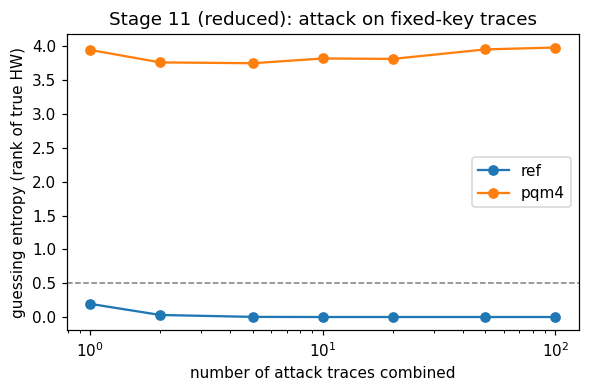

In [13]:
# Guessing entropy on the attack file (reduced Stage 11)
plt.figure(figsize=(6, 3.5))
for impl, r in res.items():
    plt.semilogx(r['ns'], r['ge'], 'o-', label=impl)
plt.axhline(0.5, ls='--', c='grey', lw=1)
plt.xlabel('number of attack traces combined'); plt.ylabel('guessing entropy (rank of true HW)')
plt.title('Stage 11 (reduced): attack on fixed-key traces'); plt.legend(); plt.show()